# Desain Eksperimen: 4 Skenario, 2 Faktor — MobileNetV2

**Satu model** (MobileNetV2), **4 skenario**, memvariasikan 2 faktor:

| Skenario | Bobot Awal | Augmentasi |
|---|---|---|
| S1 | Random | Tanpa |
| S2 | Random | Dengan |
| S3 | Pretrained ImageNet | Tanpa |
| S4 | Pretrained ImageNet | Dengan |

**Dibuat identik di semua skenario:** arsitektur, split data & seed, optimizer & learning rate, callback (early stopping + reduce LR on plateau).

Pasangan skenario bertetangga hanya berbeda satu faktor, sehingga efek augmentasi (S1 vs S2, S3 vs S4) dan efek pretraining (S1 vs S3, S2 vs S4) dapat dipisahkan.

**PENTING:** Aktifkan GPU dulu: `Runtime` → `Change runtime type` → `T4 GPU` → `Save`.

## 1. Upload Dataset

In [1]:
from google.colab import files
import zipfile, os

print("Upload file ZIP dataset kamu (struktur: dataset_200/NamaKelas/foto.jpg)")
uploaded = files.upload()

zip_name = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('.')

print("\nSelesai extract. Isi folder saat ini:")
print(os.listdir('.'))

Upload file ZIP dataset kamu (struktur: dataset_200/NamaKelas/foto.jpg)


Saving dataset_200.zip to dataset_200.zip

Selesai extract. Isi folder saat ini:
['.config', 'dataset_200.zip', 'dataset_200', 'sample_data']


In [2]:
# GANTI sesuai nama folder dataset kamu setelah extract
DATASET_DIR = "dataset_200"

print("Kelas yang terdeteksi:")
for cls in sorted(os.listdir(DATASET_DIR)):
    cls_path = os.path.join(DATASET_DIR, cls)
    if os.path.isdir(cls_path):
        n_files = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
        print(f"  {cls}: {n_files} foto")

Kelas yang terdeteksi:
  Grape___Black_rot: 200 foto
  Grape___Esca_(Black_Measles): 200 foto
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 200 foto
  Grape___healthy: 200 foto


## 2. Setup, Import, dan Konfigurasi (Identik untuk Semua Skenario)

In [3]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.metrics import (confusion_matrix, classification_report,
                               precision_recall_fscore_support)

# ---- Konfigurasi identik di semua skenario ----
SEED = 42
BATCH_SIZE = 16
MAX_EPOCHS = 30
LEARNING_RATE = 1e-4
IMG_SIZE = 224
EARLY_STOP_PATIENCE = 5     # callback: hentikan jika val_loss tidak membaik 5 epoch
LR_PATIENCE = 2             # callback: turunkan LR jika val_loss stagnan 2 epoch
OUTPUT_DIR = "./outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {DEVICE}")
if DEVICE.type != "cuda":
    print("⚠️  GPU belum aktif! Aktifkan lewat Runtime > Change runtime type > GPU")

Menggunakan device: cuda


## 3. Split Data (Dibuat SEKALI, dipakai sama untuk semua skenario)
Supaya adil, index train/val/test harus identik di 4 skenario — maka split dilakukan satu kali di awal dengan seed tetap.

In [4]:
# Load dataset tanpa transform dulu, hanya untuk mendapatkan daftar kelas & jumlah data
base_dataset = datasets.ImageFolder(DATASET_DIR)
CLASS_NAMES = base_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)
n_total = len(base_dataset)

print(f"Kelas: {CLASS_NAMES}")
print(f"Total data: {n_total}")

# Split index 70% train, 15% val, 15% test — dengan seed tetap agar identik di semua skenario
rng = np.random.RandomState(SEED)
indices = np.arange(n_total)
rng.shuffle(indices)

n_train = int(0.7 * n_total)
n_val = int(0.15 * n_total)

train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]

print(f"Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")
print("Index split ini akan dipakai ULANG persis sama di keempat skenario.")

Kelas: ['Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy']
Total data: 800
Train: 560 | Val: 120 | Test: 120
Index split ini akan dipakai ULANG persis sama di keempat skenario.


## 4. Definisi Transform (Faktor: Augmentasi)

In [8]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Transform TANPA augmentasi (S1, S3) — hanya resize + normalisasi
transform_no_aug = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Transform DENGAN augmentasi (S2, S4)
transform_with_aug = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Transform untuk val/test SELALU tanpa augmentasi (standar, di semua skenario)
transform_eval = transform_no_aug

## 5. Definisi Model MobileNetV2 (Faktor: Bobot Awal)

In [9]:
def build_mobilenetv2(num_classes, pretrained: bool):
    """
    pretrained=True  -> bobot awal dari ImageNet (S3, S4)
    pretrained=False -> bobot awal random/dari nol (S1, S2)
    Seluruh layer tetap dilatih (fine-tune penuh) di kedua kasus,
    supaya perbandingan murni soal titik awal bobot, bukan soal freeze/unfreeze.
    """
    weights = models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.mobilenet_v2(weights=weights)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 6. Fungsi Training dengan Callback (Early Stopping + ReduceLROnPlateau)

In [10]:
def train_scenario(scenario_name, pretrained, use_augmentation,
                    train_idx, val_idx, test_idx, class_names, device):

    torch.manual_seed(SEED)   # reset seed training tiap skenario agar inisialisasi random identik polanya
    np.random.seed(SEED)

    # --- Dataset & Dataloader sesuai faktor augmentasi ---
    train_transform = transform_with_aug if use_augmentation else transform_no_aug

    train_dataset_full = datasets.ImageFolder(DATASET_DIR, transform=train_transform)
    eval_dataset_full = datasets.ImageFolder(DATASET_DIR, transform=transform_eval)

    train_subset = Subset(train_dataset_full, train_idx)
    val_subset = Subset(eval_dataset_full, val_idx)
    test_subset = Subset(eval_dataset_full, test_idx)

    trainloader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    valloader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    testloader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    # --- Model sesuai faktor bobot awal ---
    model = build_mobilenetv2(len(class_names), pretrained=pretrained).to(device)
    n_params = count_parameters(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=LR_PATIENCE)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float('inf')
    best_model_wts = copy.deepcopy(model.state_dict())
    patience_counter = 0
    start_time = time.time()

    print(f"\n{'='*70}\nTRAINING {scenario_name} "
          f"(pretrained={pretrained}, augmentasi={use_augmentation})\n{'='*70}")
    print(f"Jumlah parameter trainable: {n_params:,}")

    for epoch in range(MAX_EPOCHS):
        # ---- Training ----
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # ---- Validation ----
        val_loss, val_acc, _, _ = evaluate(model, valloader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        scheduler.step(val_loss)   # callback: reduce LR on plateau

        print(f"[{scenario_name}] Epoch {epoch+1}/{MAX_EPOCHS} "
              f"- train_loss: {train_loss:.4f} - train_acc: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f} "
              f"- lr: {optimizer.param_groups[0]['lr']:.2e}")

        # ---- Callback: Early Stopping ----
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= EARLY_STOP_PATIENCE:
                print(f"⏹ Early stopping di epoch {epoch+1} (val_loss tidak membaik "
                      f"{EARLY_STOP_PATIENCE} epoch berturut-turut)")
                break

    total_time = time.time() - start_time
    model.load_state_dict(best_model_wts)

    # ---- Evaluasi final di test set ----
    test_loss, test_acc, y_true, y_pred = evaluate(model, testloader, criterion, device)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0)

    print(f"[{scenario_name}] Selesai dalam {total_time:.2f} detik "
          f"({total_time/60:.2f} menit), {len(history['train_loss'])} epoch")
    print(f"[{scenario_name}] Test Accuracy: {test_acc:.4f} | Precision: {precision:.4f} "
          f"| Recall: {recall:.4f} | F1: {f1:.4f}")

    return {
        "model": model,
        "history": history,
        "train_time": total_time,
        "n_epochs_run": len(history["train_loss"]),
        "n_params": n_params,
        "test_loss": test_loss,
        "test_acc": test_acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "y_true": y_true,
        "y_pred": y_pred,
    }


def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return running_loss / total, correct / total, np.array(all_labels), np.array(all_preds)

## 7. Jalankan 4 Skenario

In [11]:
SCENARIOS = {
    "S1 (Random, Tanpa Aug)":     {"pretrained": False, "use_augmentation": False},
    "S2 (Random, Dengan Aug)":    {"pretrained": False, "use_augmentation": True},
    "S3 (Pretrained, Tanpa Aug)": {"pretrained": True,  "use_augmentation": False},
    "S4 (Pretrained, Dengan Aug)":{"pretrained": True,  "use_augmentation": True},
}

results = {}
for name, cfg in SCENARIOS.items():
    results[name] = train_scenario(
        name, cfg["pretrained"], cfg["use_augmentation"],
        train_idx, val_idx, test_idx, CLASS_NAMES, DEVICE
    )


TRAINING S1 (Random, Tanpa Aug) (pretrained=False, augmentasi=False)
Jumlah parameter trainable: 2,228,996
[S1 (Random, Tanpa Aug)] Epoch 1/30 - train_loss: 1.2298 - train_acc: 0.4071 - val_loss: 1.8696 - val_acc: 0.1583 - lr: 1.00e-04
[S1 (Random, Tanpa Aug)] Epoch 2/30 - train_loss: 0.9520 - train_acc: 0.6321 - val_loss: 2.4117 - val_acc: 0.3500 - lr: 1.00e-04
[S1 (Random, Tanpa Aug)] Epoch 3/30 - train_loss: 0.6389 - train_acc: 0.7786 - val_loss: 0.5722 - val_acc: 0.8083 - lr: 1.00e-04
[S1 (Random, Tanpa Aug)] Epoch 4/30 - train_loss: 0.4737 - train_acc: 0.8393 - val_loss: 0.5684 - val_acc: 0.7667 - lr: 1.00e-04
[S1 (Random, Tanpa Aug)] Epoch 5/30 - train_loss: 0.4496 - train_acc: 0.8464 - val_loss: 0.4923 - val_acc: 0.8167 - lr: 1.00e-04
[S1 (Random, Tanpa Aug)] Epoch 6/30 - train_loss: 0.3371 - train_acc: 0.8839 - val_loss: 0.4789 - val_acc: 0.8167 - lr: 1.00e-04
[S1 (Random, Tanpa Aug)] Epoch 7/30 - train_loss: 0.2609 - train_acc: 0.9143 - val_loss: 0.5172 - val_acc: 0.8083 - lr

100%|██████████| 13.6M/13.6M [00:00<00:00, 110MB/s]



TRAINING S3 (Pretrained, Tanpa Aug) (pretrained=True, augmentasi=False)
Jumlah parameter trainable: 2,228,996
[S3 (Pretrained, Tanpa Aug)] Epoch 1/30 - train_loss: 0.4844 - train_acc: 0.8464 - val_loss: 0.0443 - val_acc: 0.9917 - lr: 1.00e-04
[S3 (Pretrained, Tanpa Aug)] Epoch 2/30 - train_loss: 0.1112 - train_acc: 0.9696 - val_loss: 0.0178 - val_acc: 1.0000 - lr: 1.00e-04
[S3 (Pretrained, Tanpa Aug)] Epoch 3/30 - train_loss: 0.0346 - train_acc: 0.9946 - val_loss: 0.0141 - val_acc: 1.0000 - lr: 1.00e-04
[S3 (Pretrained, Tanpa Aug)] Epoch 4/30 - train_loss: 0.0248 - train_acc: 0.9946 - val_loss: 0.0237 - val_acc: 0.9917 - lr: 1.00e-04
[S3 (Pretrained, Tanpa Aug)] Epoch 5/30 - train_loss: 0.0321 - train_acc: 0.9929 - val_loss: 0.0103 - val_acc: 1.0000 - lr: 1.00e-04
[S3 (Pretrained, Tanpa Aug)] Epoch 6/30 - train_loss: 0.0161 - train_acc: 0.9964 - val_loss: 0.0143 - val_acc: 0.9917 - lr: 1.00e-04
[S3 (Pretrained, Tanpa Aug)] Epoch 7/30 - train_loss: 0.0125 - train_acc: 0.9946 - val_loss

## 8. Tabel Perbandingan 4 Skenario

In [12]:
summary_rows = []
for name, res in results.items():
    summary_rows.append({
        "Skenario": name,
        "Test Accuracy": round(res["test_acc"], 4),
        "Precision": round(res["precision"], 4),
        "Recall": round(res["recall"], 4),
        "F1-Score": round(res["f1"], 4),
        "Test Loss": round(res["test_loss"], 4),
        "Epoch Berjalan": res["n_epochs_run"],
        "Waktu Training (detik)": round(res["train_time"], 2),
    })

summary_df = pd.DataFrame(summary_rows).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
summary_df.to_csv(os.path.join(OUTPUT_DIR, "scenario_comparison.csv"), index=False)

print("=" * 100)
print("TABEL PERBANDINGAN 4 SKENARIO (diurutkan berdasarkan akurasi test)")
print("=" * 100)
summary_df

TABEL PERBANDINGAN 4 SKENARIO (diurutkan berdasarkan akurasi test)


,Skenario,Test Accuracy,Precision,Recall,F1-Score,Test Loss,Epoch Berjalan,Waktu Training (detik)
0,"S4 (Pretrained, Dengan Aug)",1.000,1.0000,1.000,1.0000,0.0013,26,97.88
1,"S3 (Pretrained, Tanpa Aug)",1.000,1.0000,1.000,1.0000,0.0049,14,46.59
2,"S2 (Random, Dengan Aug)",0.925,0.9254,0.925,0.9247,0.2178,30,112.04
3,"S1 (Random, Tanpa Aug)",0.750,0.7708,0.750,0.7533,0.6459,16,54.07


In [13]:
best_scenario_name = summary_df.iloc[0]["Skenario"]
best_scenario_acc = summary_df.iloc[0]["Test Accuracy"]

print("🏆 " + "=" * 50)
print(f"SKENARIO TERBAIK: {best_scenario_name}")
print(f"Test Accuracy: {best_scenario_acc:.4f}")
print("=" * 53)

🏆 ==================================================
SKENARIO TERBAIK: S4 (Pretrained, Dengan Aug)
Test Accuracy: 1.0000


## 9. Analisis Efek Tiap Faktor
Karena pasangan skenario bertetangga hanya berbeda satu faktor, kita bisa pisahkan efek augmentasi dan efek pretraining secara langsung.

In [14]:
acc = {name: res["test_acc"] for name, res in results.items()}
names = list(SCENARIOS.keys())  # urutan tetap S1,S2,S3,S4

print("--- Efek Augmentasi (bobot awal sama, augmentasi beda) ---")
print(f"S1 (Random, Tanpa Aug) vs S2 (Random, Dengan Aug): "
      f"{acc[names[0]]:.4f} -> {acc[names[1]]:.4f} "
      f"(selisih: {acc[names[1]]-acc[names[0]]:+.4f})")
print(f"S3 (Pretrained, Tanpa Aug) vs S4 (Pretrained, Dengan Aug): "
      f"{acc[names[2]]:.4f} -> {acc[names[3]]:.4f} "
      f"(selisih: {acc[names[3]]-acc[names[2]]:+.4f})")

print("\n--- Efek Pretraining (augmentasi sama, bobot awal beda) ---")
print(f"S1 (Random, Tanpa Aug) vs S3 (Pretrained, Tanpa Aug): "
      f"{acc[names[0]]:.4f} -> {acc[names[2]]:.4f} "
      f"(selisih: {acc[names[2]]-acc[names[0]]:+.4f})")
print(f"S2 (Random, Dengan Aug) vs S4 (Pretrained, Dengan Aug): "
      f"{acc[names[1]]:.4f} -> {acc[names[3]]:.4f} "
      f"(selisih: {acc[names[3]]-acc[names[1]]:+.4f})")

--- Efek Augmentasi (bobot awal sama, augmentasi beda) ---
S1 (Random, Tanpa Aug) vs S2 (Random, Dengan Aug): 0.7500 -> 0.9250 (selisih: +0.1750)
S3 (Pretrained, Tanpa Aug) vs S4 (Pretrained, Dengan Aug): 1.0000 -> 1.0000 (selisih: +0.0000)

--- Efek Pretraining (augmentasi sama, bobot awal beda) ---
S1 (Random, Tanpa Aug) vs S3 (Pretrained, Tanpa Aug): 0.7500 -> 1.0000 (selisih: +0.2500)
S2 (Random, Dengan Aug) vs S4 (Pretrained, Dengan Aug): 0.9250 -> 1.0000 (selisih: +0.0750)


## 10. Grafik Perbandingan Akurasi 4 Skenario

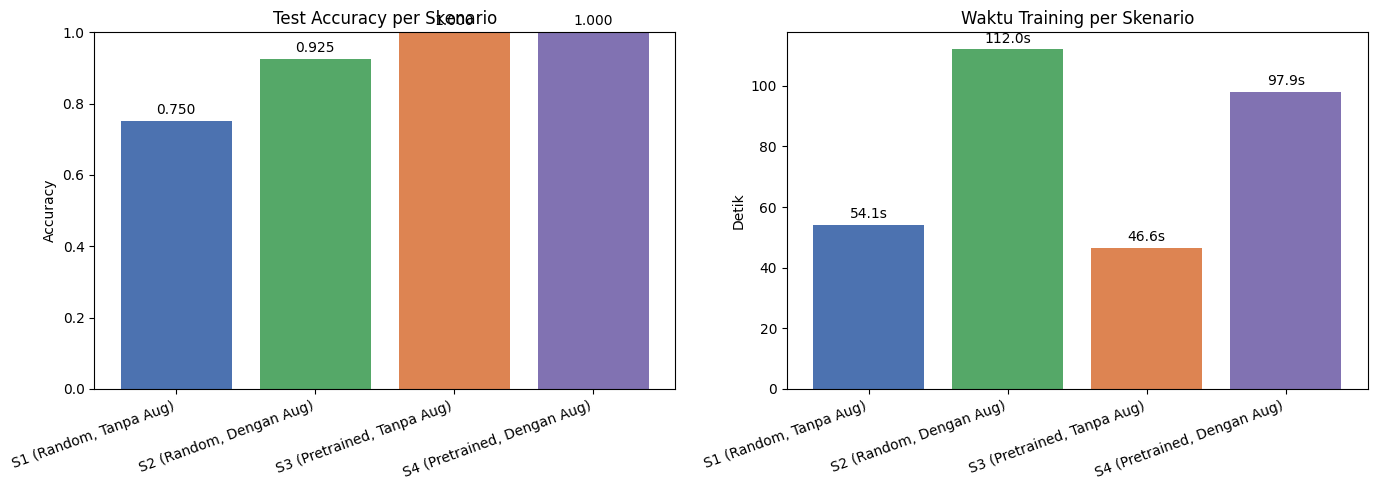

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']
accs = [results[n]["test_acc"] for n in names]
times = [results[n]["train_time"] for n in names]

axes[0].bar(names, accs, color=colors)
axes[0].set_title("Test Accuracy per Skenario")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
plt.setp(axes[0].get_xticklabels(), rotation=20, ha='right')
for i, v in enumerate(accs):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha='center')

axes[1].bar(names, times, color=colors)
axes[1].set_title("Waktu Training per Skenario")
axes[1].set_ylabel("Detik")
plt.setp(axes[1].get_xticklabels(), rotation=20, ha='right')
for i, v in enumerate(times):
    axes[1].text(i, v + max(times)*0.02, f"{v:.1f}s", ha='center')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "scenario_comparison_chart.png"), dpi=150)
plt.show()

## 11. Kurva Training vs Validation — 4 Skenario

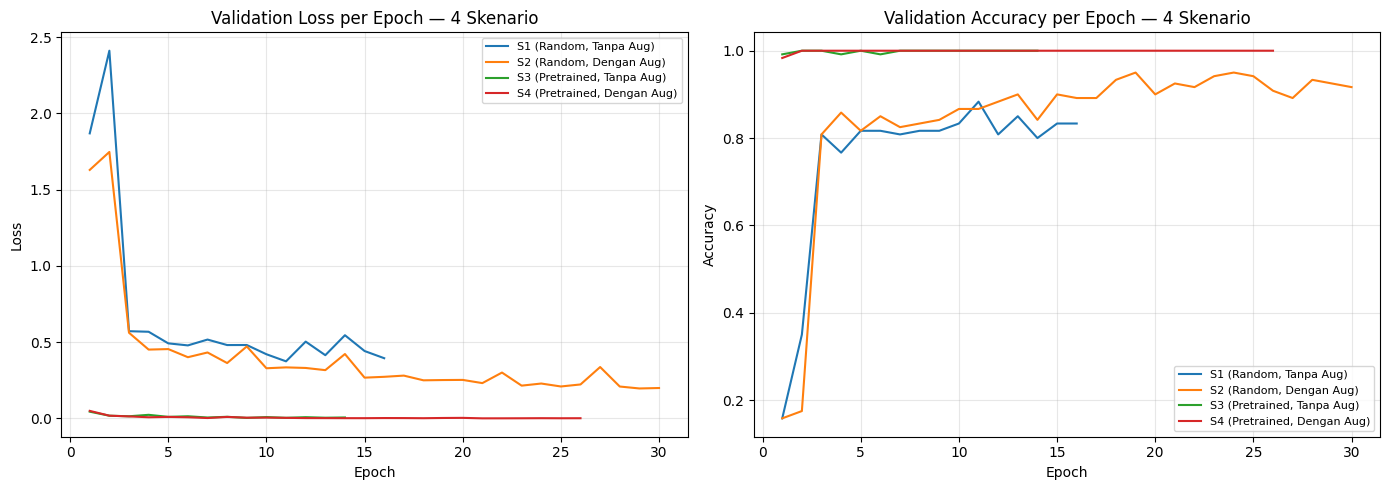

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, res in results.items():
    h = res["history"]
    epochs_range = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(epochs_range, h["val_loss"], label=name)
    axes[1].plot(epochs_range, h["val_acc"], label=name)

axes[0].set_title("Validation Loss per Epoch — 4 Skenario")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].set_title("Validation Accuracy per Epoch — 4 Skenario")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_curves_all_scenarios.png"), dpi=150)
plt.show()

## 12. Confusion Matrix — 4 Skenario

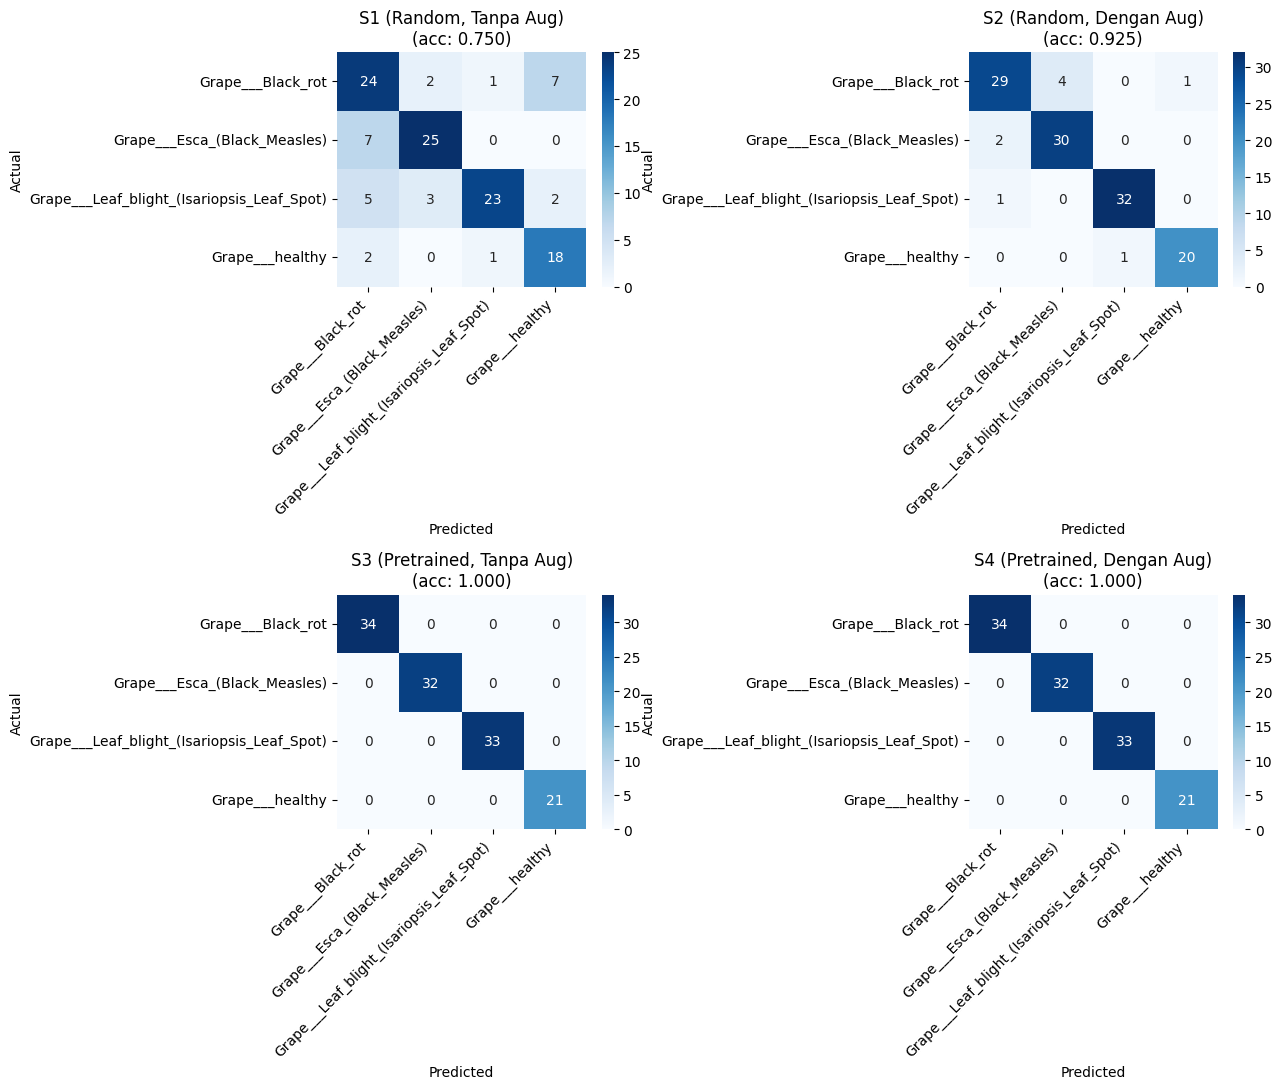

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

for ax, name in zip(axes, names):
    res = results[name]
    cm = confusion_matrix(res["y_true"], res["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"{name}\n(acc: {res['test_acc']:.3f})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_all_scenarios.png"), dpi=150)
plt.show()

## 13. Classification Report Detail — 4 Skenario

In [18]:
for name in names:
    res = results[name]
    print("=" * 70)
    print(f"CLASSIFICATION REPORT — {name}")
    print("=" * 70)
    print(classification_report(res["y_true"], res["y_pred"], target_names=CLASS_NAMES, zero_division=0))
    print()

CLASSIFICATION REPORT — S1 (Random, Tanpa Aug)
                                            precision    recall  f1-score   support

                         Grape___Black_rot       0.63      0.71      0.67        34
              Grape___Esca_(Black_Measles)       0.83      0.78      0.81        32
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)       0.92      0.70      0.79        33
                           Grape___healthy       0.67      0.86      0.75        21

                                  accuracy                           0.75       120
                                 macro avg       0.76      0.76      0.75       120
                              weighted avg       0.77      0.75      0.75       120


CLASSIFICATION REPORT — S2 (Random, Dengan Aug)
                                            precision    recall  f1-score   support

                         Grape___Black_rot       0.91      0.85      0.88        34
              Grape___Esca_(Black_Measles)       0.88      0

## 14. Simpan Model Terbaik & Semua Hasil

In [19]:
best_model_obj = results[best_scenario_name]["model"]
safe_name = best_scenario_name.split(" ")[0]  # ambil kode S1/S2/S3/S4 saja untuk nama file
best_model_path = os.path.join(OUTPUT_DIR, f"best_model_{safe_name}.pth")
torch.save(best_model_obj.state_dict(), best_model_path)

for name, res in results.items():
    safe = name.split(" ")[0]
    path = os.path.join(OUTPUT_DIR, f"model_{safe}.pth")
    torch.save(res["model"].state_dict(), path)

print(f"Model terbaik ({best_scenario_name}) disimpan di: {best_model_path}")
print(f"Semua file hasil ada di folder: {OUTPUT_DIR}")

Model terbaik (S4 (Pretrained, Dengan Aug)) disimpan di: ./outputs/best_model_S4.pth
Semua file hasil ada di folder: ./outputs


## 15. (Opsional) Download Semua Hasil sebagai ZIP

In [ ]:
import shutil
from google.colab import files as colab_files

shutil.make_archive("hasil_eksperimen_4_skenario", "zip", OUTPUT_DIR)
colab_files.download("hasil_eksperimen_4_skenario.zip")